#### this script produces a random shuffle of the authorship of each paper

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import random
from tqdm import tqdm
import time
from random import shuffle
from multiprocessing import Pool, cpu_count

In [2]:
author_path="../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/pub_author.csv"
group_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv'

In [3]:
authorship_shuffle_path="../../data/dropbox/LaborDivision/data/deriveddata/authorship_shuffle/authorship_shuffle.csv"

In [4]:
author_df=pd.read_csv(author_path)
author_df.head()

,ost_bk,cluster_id,cntry,role,year,dis
0,29768070,65683243.0,JPN,F,2008,51
1,29768070,79129017.0,JPN,M,2008,51
2,29768070,58951927.0,CHN,M,2008,51
3,29768070,9735544.0,JPN,M,2008,51
4,29768070,34120990.0,JPN,L,2008,51


In [5]:
group_df = pd.read_csv(group_path)
group_df = group_df.drop_duplicates()
group_df.head()

,Code,class
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


### select collaborated papers between different scientific capacity

In [6]:
author_df = author_df.merge(group_df, left_on='cntry', right_on='Code', how='left')
author_df.head(2)

,ost_bk,cluster_id,cntry,role,year,dis,Code,class
0,29768070,65683243.0,JPN,F,2008,51,JPN,Advanced
1,29768070,79129017.0,JPN,M,2008,51,JPN,Advanced


In [7]:
author_df['unique_group'] = author_df.groupby(['ost_bk'])['class'].transform('nunique')

In [9]:
filtered_df = author_df[author_df.unique_group!=1]

In [27]:
def shuffle_author(df):
    result = []
    for row in df.values:
        ost_bk, year, dis, cntrylist = row
        cntrylist = np.random.permutation(cntrylist)
        result.extend([
            [ost_bk, year, dis, cntrylist[0], 'F'],
            [ost_bk, year, dis, cntrylist[1], 'L']
        ])
        result.extend([[ost_bk, year, dis, item, 'M'] for item in cntrylist[2:]])
    return result

In [26]:
n = 20 #number of times for reshuffling
cntrys_df=filtered_df.groupby(['ost_bk','year','dis'])['cntry'].apply(list).reset_index()

In [28]:
results_all = []
for _ in tqdm(range(n)):
    shuffled_results = shuffle_author(cntrys_df)
    results_all.extend(shuffled_results)

100%|███████████████████████████████████████████| 20/20 [12:30<00:00, 37.50s/it]


In [32]:
results_df = pd.DataFrame(results_all, columns=['ost_bk','year','dis','cntry','role'])

In [33]:
expected_df = results_df.groupby(['cntry','year','dis','role']).size().reset_index(name='expected')
expected_df['expected'] = expected_df['expected']/n
#expected_df.to_csv(pub_author_expected_path, index=False)
expected_df.to_csv("shuffle_exclusive_same_capacity.csv", index=False)

In [34]:
expected_df.head()

,cntry,year,dis,role,expected
0,ABW,2014,4,F,0.05
1,ABW,2014,4,L,0.05
2,ABW,2014,4,M,0.90
3,ABW,2016,8,F,0.65
4,ABW,2016,8,L,0.40


In [80]:
cntry_exp=test.groupby(['cntry','role'])['expected'].sum().reset_index(name='expect')

In [76]:
cntry_raw = author_df.groupby(['cntry','role']).size().reset_index(name='raw')

In [81]:
cntry_expect = cntry_exp.copy()

In [78]:
cntry_raw.head()

,cntry,role,raw
0,ABW,F,4
1,ABW,L,5
2,ABW,M,30
3,AFG,F,115
4,AFG,L,96


In [82]:
cntry_expect.head()

,cntry,role,expect
0,ABW,F,7.65
1,ABW,L,6.85
2,ABW,M,24.50
3,AFG,F,143.15
4,AFG,L,146.70


In [83]:
cntry_all = cntry_raw.merge(cntry_expect, on=['cntry','role'])

In [84]:
cntry_all['norm'] = cntry_all['raw']/cntry_all['expect']

In [85]:
cntry_all.sort_values(by='norm')

,cntry,role,raw,expect,norm
499,STP,L,1,7.95,0.125786
498,STP,F,1,7.05,0.141844
354,MHL,F,1,5.95,0.168067
534,TKM,F,2,11.00,0.181818
216,GNQ,F,3,15.60,0.192308
...,...,...,...,...,...
575,VCT,M,42,31.30,1.341853
551,TUV,M,9,6.60,1.363636
190,FSM,L,29,21.15,1.371158
156,DZA,F,11476,7942.10,1.444958


In [86]:
cntry_all.sort_values(by='norm').tail(20)

,cntry,role,raw,expect,norm
336,MAR,F,5984,5021.25,1.191735
126,CUB,F,2884,2400.85,1.201241
501,SUR,F,69,57.15,1.207349
583,VUT,L,73,60.15,1.213633
273,JOR,F,3827,3140.35,1.218654
2,ABW,M,30,24.50,1.224490
119,COM,M,120,97.85,1.226367
133,CYM,L,20,16.15,1.238390
131,CUW,M,78,62.50,1.248000
102,CHN,F,483897,377906.65,1.280467


In [48]:
cntry_all.sort_values(by='norm')

,cntry,role,raw,expect,norm
498,STP,F,1,7.75,0.129032
499,STP,L,1,7.35,0.136054
354,MHL,F,1,6.40,0.156250
216,GNQ,F,3,14.85,0.202020
534,TKM,F,2,9.90,0.202020
...,...,...,...,...,...
543,TUN,F,13753,10443.35,1.316915
369,MNE,F,655,491.10,1.333741
551,TUV,M,9,6.45,1.395349
156,DZA,F,11476,7949.85,1.443549


In [50]:
cntry_norm = cntry_all.pivot(index='cntry', columns='role', values='norm')

In [54]:
cntry_norm

role,F,L,M
cntry,,,
ABW,0.522876,0.632911,1.279318
AFG,0.801673,0.661841,1.122336
AGO,0.794083,0.667471,1.110387
ALB,0.995538,0.687161,1.086144
AND,1.234043,0.685225,1.019443
...,...,...,...
XKX,1.310236,0.837061,0.960728
YEM,1.070778,0.921100,1.003484
ZAF,0.953037,1.023532,1.006220


In [55]:
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gp
import matplotlib.colors as colors

In [57]:
def map_group(fratio,lratio):
    if fratio<1 and lratio<1:
        return 0.5
    elif fratio>1 and lratio<1:
        return 1.5
    elif fratio<1 and lratio>1:
        return 2.5
    elif fratio>1 and lratio>1:
        return 3.5
cntry_norm['g']=cntry_norm.apply(lambda x:map_group(x.F,x.L),axis=1)

In [66]:
cntry_norm = cntry_norm.reset_index()

In [58]:
colorsList = ['#A6A6A6', '#F4D05E', '#EA6B5F','#912855']
cmap = colors.ListedColormap(colorsList)
bounds = np.array([0, 1, 2, 3, 4])
norm = colors.BoundaryNorm(boundaries=bounds, ncolors=4)

In [60]:
world_geo=gp.read_file("../../data/dropbox/LaborDivision/data/additionaldata/worldmap/ne_50m_admin_0_countries.shp")

In [61]:
world_geo = world_geo[['ADMIN','NAME','ISO_A3','geometry']]
world_geo=world_geo[world_geo.NAME!='Antarctica']

In [65]:
cntry_norm.head()

role,F,L,M,g
cntry,,,,
ABW,0.522876,0.632911,1.279318,0.5
AFG,0.801673,0.661841,1.122336,0.5
AGO,0.794083,0.667471,1.110387,0.5
ALB,0.995538,0.687161,1.086144,0.5
AND,1.234043,0.685225,1.019443,1.5


<Axes: >

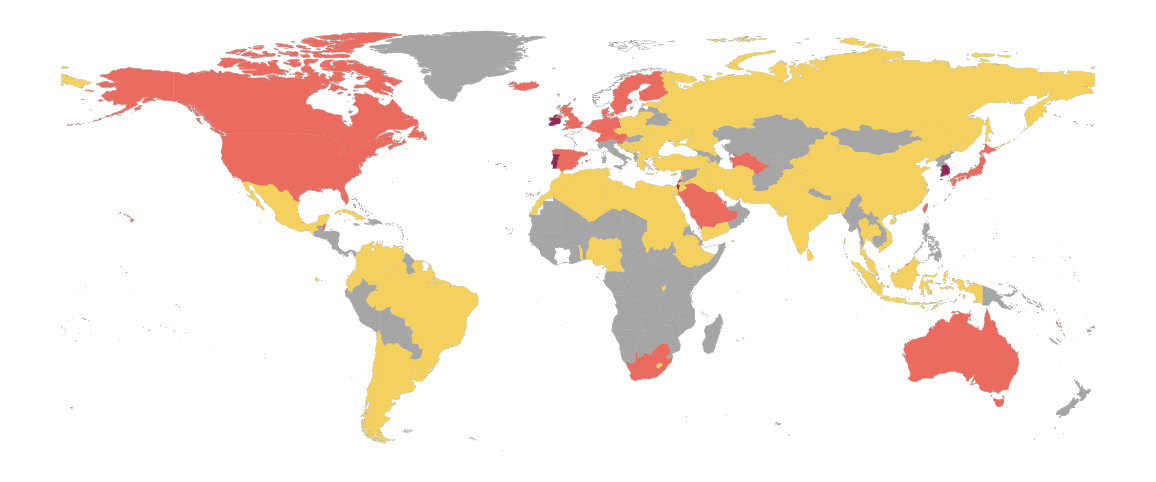

In [88]:
fig, ax=plt.subplots(figsize=(16,6))
world_geo.plot(ax = ax, linewidth=0.25, edgecolor="#8C8C8C", facecolor="#ffffff")
ax.axis("off")
df = cntry_norm.merge(world_geo,left_on='cntry',right_on='ISO_A3')
df = gp.GeoDataFrame(df)
df.plot(column='g', cmap=cmap, norm=norm, ax=ax)
#sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
#cbar = fig.colorbar(sm,ticks=[0.5,1.5,2.5,3.5])
#cbar.set_ticklabels(['Under-Both','Over-First','Over-Last','Over-Both'])
#plt.savefig("Authorship-NullModel.png",bbox_inches='tight')

In [62]:
def plot_worldmap(fig, ax, outline, df, column,cmap,norm,vmin,vmax,ticks,tlabels,legend=False):
    outline.plot(ax = ax, linewidth=0.25, edgecolor="#8C8C8C", facecolor="#ffffff")
    ax.axis('off')
    df.plot(column=column, cmap=cmap, norm=norm, vmin=vmin, vmax=vmax, ax=ax)
    if legend==True:
        sm=plt.cm.ScalarMappable(cmap=cmap,norm=norm)
        cbar=fig.colorbar(sm,ticks=ticks)
        cbar.set_ticklabels(tlabels)
    return fig, ax, cbar

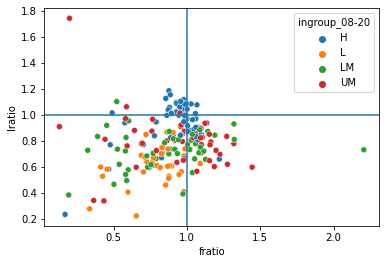

In [122]:
sns.scatterplot(x='fratio',y='lratio',data=cntry_meta,hue='ingroup_08-20')
plt.axhline(y=1)
plt.axvline(x=1)